# Routine, predictability and mobility profiles

**Question.** How regular, diverse and predictable is each person's routine, and what kinds of people (routine followers, explorers) are in my sample?

**You will get** a visit table (one row per stop, with a place and a purpose), and per-person regularity, diversity, entropy, predictability, return and exploration measures, the mix of visit purposes, how people move between purposes, how activities are spread over the day, and a clustering of people into mobility profiles.

**Prerequisites.** [Build the trajectory hierarchy](trajectory-hierarchy.md): this notebook starts from the stops and places it produces. The run-time table at the end shows the measured time of each phase of the run saved here; Colab was not measured.

**Data.** [GeoLife](https://www.microsoft.com/en-us/download/details.aspx?id=52367): the first 80 trips of users 000 to 005 (about 630,000 fixes, roughly 25 MB read from the 313 MB archive) with `fastmob.data.load_geolife`. Timestamps are converted from UTC to Beijing time first, because home and work are defined by the hour of the day. The notebook stops if the download fails.

> **Requires `fastmob` 0.3.4 or newer**, which provides the dataset loaders `fastmob.data.load_geolife` and `load_brightkite` (0.3.3 has them but caches GeoLife files across calls).

In [1]:
import time
from contextlib import contextmanager

_NOTEBOOK_START = time.perf_counter()
PHASES = {}


@contextmanager
def phase(name):
    """Add the wall-clock time of the block to PHASES[name]."""
    start = time.perf_counter()
    try:
        yield
    finally:
        PHASES[name] = PHASES.get(name, 0.0) + time.perf_counter() - start

In [2]:
with phase("setup"):
    get_ipython().run_line_magic("pip", "install -q 'fastmob>=0.3.4' pandas matplotlib")

In [3]:
import fastmob.data

assert hasattr(fastmob.data, "load_geolife") and hasattr(fastmob.data, "load_brightkite"), (
    "This notebook needs fastmob 0.3.4 or newer (older releases lack the dataset loaders or have a loader caching bug)."
)

In [4]:
import tempfile
from pathlib import Path

cache_status = "cached (files from an earlier run were reused)" if (Path(tempfile.gettempdir()) / "fastmob_data" / "geolife").exists() else "cold (nothing cached before this run)"

## From fixes to a visit table

Visit-based measures need one row per *visit*: who, where (a place id) and, optionally, when and for what purpose. We build it from GeoLife in four steps: convert to local time, detect stops, group stops into per-person places, and label the places home, work or other.

In [5]:
import fastmob
import pandas as pd
from fastmob.data import load_geolife

with phase("download and load"):
    tdf = load_geolife(users=[f"{i:03d}" for i in range(6)], max_trips_per_user=80)

with phase("analysis"):
    tdf.timezone_conversion(from_timezone="UTC", to_timezone="Asia/Shanghai")
    fixes = fastmob.filter(tdf.to_pandas(), max_speed_kmh=200)
    staypoints = fastmob.Positionfixes(fixes).generate_staypoints(minutes_for_a_stop=20, spatial_radius_km=0.2, no_data_for_minutes=30)
    locations, staypoints = staypoints.generate_user_locations(epsilon_km=0.2)
    locations = locations.identify(staypoints)
    purposes = locations.to_pandas()[["uid", "location_id", "purpose"]]
    visits = staypoints.to_pandas().merge(purposes, on=["uid", "location_id"]).rename(columns={"uid": "user_id"})

print(len(fixes), "fixes ->", len(visits), "visits by", visits["user_id"].nunique(), "users")
visits.groupby("user_id").size().rename("visits").to_frame().T

630771 fixes -> 504 visits by 6 users


user_id,000,001,002,003,004,005
visits,51,52,99,117,83,102


The 630,771 fixes became 504 visits by six users, between 51 and 117 per user. Each visit has the user, the stop times, the place id and its purpose.

## How far did they travel in total?

`distance_straight_line` is the total length of a person's trajectory, in kilometres, adding up the straight-line distances between consecutive fixes. It uses the fixes, not the visits.

In [6]:
with phase("analysis"):
    total = fastmob.distance_straight_line(fixes)
total

,uid,distance_straight_line
0,000,1641.663542
1,001,1013.679754
2,002,1781.410094
3,003,2039.564706
4,004,1192.089474
5,005,6052.488847


Distances add up over all recorded days, so they depend on how much each person was recorded: user 005's 6,052 km against about 1,000 to 2,000 km for most others says as much about recording volume as about travel. Divide by the number of recorded days before comparing people.

## How regular, diverse and predictable?

`regularity` is 1 minus the number of distinct places divided by the number of visits, so it is high when a person keeps returning to the same few places. `diversity` is the share of distinct sub-sequences in the person's sequence of places (higher means a more varied sequence). `trajectory_entropy` is a normalised (0 to 1) entropy of that sequence. `real_entropy` and `trajectory_predictability` use the *order* of visits: the entropy is in bits, and the predictability is the highest share of next places an ideal predictor could get right (Fano's bound).

In [7]:
import fastmob.measures.individual as measures

with phase("analysis"):
    regularity = measures.regularity(visits, user_id_col="user_id", location_id_col="location_id", location_type_col="purpose")
    diversity = measures.diversity(visits, user_id_col="user_id", location_id_col="location_id")
    entropy = measures.trajectory_entropy(visits, user_id_col="user_id", location_id_col="location_id", timestamp_col="started_at")
    real = measures.real_entropy(visits, uid_col="user_id", location_id_col="location_id", datetime_col="started_at")
    predictability = measures.trajectory_predictability(visits, user_id_col="user_id", location_id_col="location_id", timestamp_col="started_at")

summary = regularity.merge(diversity).merge(entropy).merge(predictability, on="user_id").rename(columns={"real_entropy": "real_entropy_bits"})
summary.round(2)

,user_id,regularity,diversity,entropy,real_entropy_bits,predictability,n_unique_locations,n_steps
0,000,0.67,0.95,0.41,2.35,0.65,17,51
1,001,0.63,0.97,0.54,3.06,0.51,19,52
2,002,0.82,0.95,0.28,1.86,0.75,18,99
3,003,0.82,0.95,0.23,1.61,0.80,21,117
4,004,0.77,0.96,0.36,2.30,0.67,19,83
5,005,0.89,0.95,0.25,1.64,0.75,11,102


User 005 is the most regular: 11 distinct places in 102 visits give a regularity of 0.89, and an ideal predictor could guess their next place 75% of the time. User 001 is the least: 19 places in 52 visits give 0.63, with a predictability of 0.51. User 003 has the lowest normalised entropy (0.23) and the highest predictability (0.80). Diversity is about 0.95 for everyone, so it does not separate these six people.

## Return and exploration

`intermittance_and_degree_of_return` splits each person's movement into returns to known places and explorations of new ones: *intermittency* is the typical number of visits between new places, *degree of return* how often they come back, and `mean_return` and `mean_exploration` the average run lengths. `exploration_profiling` adds a three-way label based on these (routiners, regulars, scouters).

In [8]:
with phase("analysis"):
    returns = measures.intermittance_and_degree_of_return(visits, user_id_col="user_id", location_id_col="location_id", datetime_col="started_at")
    profiles = measures.exploration_profiling(visits, user_id_col="user_id", location_id_col="location_id", datetime_col="started_at")

profiles.round(2)

,user_id,intermittency,degree_of_return,mean_return,mean_exploration,profile
0,000,4.75,1.21,3.45,1.30,scouters
1,001,6.50,1.28,5.00,1.50,scouters
2,002,8.36,1.38,7.00,1.36,regulars
3,003,8.46,1.36,7.00,1.46,regulars
4,004,7.68,1.33,6.18,1.50,regulars
5,005,14.57,1.49,13.43,1.14,routiners


User 005 returns to known places for long runs before exploring a new one (intermittency 14.6, mean return 13.4 visits) and is labelled a routiner; users 000 and 001, who explore after much shorter runs (4.8 and 6.5), are scouters; the others are regulars.

## Predict the next place

`NextLocationPredictor` is a Markov model of order *k*: it predicts a person's next place from their last *k* places. `fit` learns from the visit sequences (ordered by `started_at`); with `backoff=True` an unseen context falls back to shorter ones. `predict` returns the most likely next place of each person after their last visit (`top_k` places), `predict_proba` the same with probabilities, and `evaluate` hides the last `n_holdout` visits of each person and reports the share of them that the model puts in its `top_k` guesses.

In [9]:
from fastmob.models import NextLocationPredictor

with phase("analysis"):
    predictor = NextLocationPredictor(order=1, backoff=True).fit(
        visits, location_col="location_id", uid_col="user_id", started_at_col="started_at"
    )
    next_place = predictor.predict(top_k=1)
    next_proba = predictor.predict_proba(top_k=3)
    accuracy = {k: predictor.evaluate(top_k=k, n_holdout=10) for k in (1, 3)}

print({k: round(v, 2) for k, v in accuracy.items()}, "(share of held-out visits predicted in the top k)")
next_proba.head(6)

{1: 0.42, 3: 0.63} (share of held-out visits predicted in the top k)


,user_id,rank,location_id,probability
0,000,1,1,1.000000
1,001,1,0,0.250000
2,001,2,1,0.153846
3,001,3,2,0.076923
4,002,1,0,0.608696
5,002,2,1,0.217391


Holding out the last ten visits of each person, the model finds the next place in its first guess for 42% of them and within its three best guesses for 63%. For user 000 the single most likely next place has probability 1.0 only because that place always followed the current one in their short history (51 visits); for user 001 the three best guesses have probabilities 0.25, 0.15 and 0.08. Consecutive visits to the same place are common in this table, which makes a first-order model look better than it would on a table with one row per change of place, so compare with the order-0 baseline (`NextLocationPredictor(order=0)`, the most frequent place) before drawing conclusions.

## One table of profiles

`compute_profiles` combines these measures with regularity, diversity, entropy and stationarity, and clusters the people on their standardised intermittency and degree of return with k-means (up to three clusters get the names routiners, regulars and scouters).

In [10]:
with phase("analysis"):
    combined = measures.compute_profiles(
        visits, user_id_col="user_id", location_id_col="location_id", start_col="started_at", end_col="finished_at",
        purpose_col="purpose", n_clusters=3, random_state=0,
    )
combined.round(2)

,user_id,intermittency,degree_of_return,regularity,diversity,entropy,stationarity,profile
0,000,4.75,1.21,0.67,0.95,0.41,0.00579,scouters
1,001,6.50,1.28,0.63,0.97,0.54,0.029443,regulars
2,002,8.36,1.38,0.82,0.95,0.28,0.03762,regulars
3,003,8.46,1.36,0.82,0.95,0.23,0.062528,regulars
4,004,7.68,1.33,0.77,0.96,0.36,0.040323,regulars
5,005,14.57,1.49,0.89,0.95,0.25,0.025876,routiners


The clusters agree with the previous table except for user 001, who is a scout in `exploration_profiling` and a regular here. With six people the cluster boundaries are unstable, and the two functions fit their clusters separately, so profile names should not be compared across runs or samples.

## What are people doing?

`visit_purpose_distribution` counts the visits of each purpose. `activity_transition_matrix` gives the percentage of consecutive visits that go from one purpose (rows) to another (columns). `daily_activity_distribution` returns, for each 10-minute bin of the day, the percentage of the observed activity that falls in each purpose.

In [11]:
with phase("analysis"):
    distribution = measures.visit_purpose_distribution(visits, activity_col="purpose")
    transitions = measures.activity_transition_matrix(visits, activity_col="purpose", user_id_col="user_id", timestamp_col="started_at")
    matrix, activities, bins = measures.daily_activity_distribution(visits, activity_col="purpose", start_time_col="started_at", end_time_col="finished_at", bin_size_minutes=10)

print(distribution.round(1).to_string(index=False))
transitions.round(1)

activity  count  percentage
    home    203        40.3
   other    194        38.5
    work    107        21.2


,activity,home,other,work
0,home,26.1,9.8,4.0
1,other,9.2,23.3,6.0
2,work,5.0,5.2,11.2


Home takes 40% of the visits, other places 38.5% and work 21%. In the transition matrix (the nine cells sum to 100% of consecutive visit pairs, rows are the origin purpose and columns the destination), most transitions stay within the same purpose: home to home 26.1%, other to other 23.3%, work to work 11.2%. Consecutive stops at the same purpose are common because a visit to one place can be split into several stops.

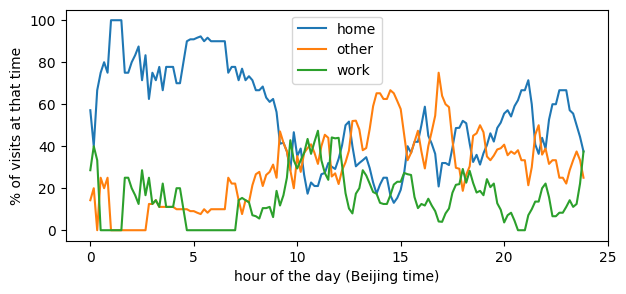

In [12]:
import matplotlib.pyplot as plt

with phase("plotting"):
    fig, ax = plt.subplots(figsize=(7, 3))
    hours = [i * 10 / 60 for i in range(matrix.shape[1])]
    for row, label in zip(matrix, activities):
        ax.plot(hours, row, label=label)
    ax.set_xlabel("hour of the day (Beijing time)")
    ax.set_ylabel("% of visits at that time")
    ax.legend()
    plt.show()

Each curve shows, for each 10-minute bin of the Beijing day, the share of the observed activity that falls in each purpose. With six people the curves are jagged, and the shares in a bin always add up to about 100%.

## Interpretation and limits

- Six people and 504 visits are far too few for population statements. The point is how to run and read the measures.
- Purposes are `home`, `work` or `other` from a frequency rule on stay times (in Beijing time here). They are guesses and drive `regularity`, the purpose distribution and the transition matrix.
- Entropy and predictability depend on how places are defined: finer places make people look less predictable. Report the clustering radius.
- Profile names come from the clustering of these six people only; with other users the same person could change cluster.

## Next steps

- Day-by-day patterns of the same visits: [Daily mobility motifs](motifs.md).
- Population-level summaries: [Population measures and flows](population-measures.md).

## Related API

[`NextLocationPredictor`](../reference/models.md#fastmob.models.next_location.NextLocationPredictor) ·
[`distance_straight_line`](../reference/measures/individual.md#fastmob.measures.individual.distance_straight_line.distance_straight_line) ·
[`regularity`](../reference/measures/individual.md#fastmob.measures.individual.regularity.regularity) ·
[`diversity`](../reference/measures/individual.md#fastmob.measures.individual.diversity.diversity) ·
[`trajectory_entropy`](../reference/measures/individual.md#fastmob.measures.individual.trajectory_entropy) ·
[`real_entropy`](../reference/measures/individual.md#fastmob.measures.individual.real_entropy.real_entropy) ·
[`trajectory_predictability`](../reference/measures/individual.md#fastmob.measures.individual.trajectory_predictability) ·
[`intermittance_and_degree_of_return`](../reference/measures/individual.md#fastmob.measures.individual.intermittance_and_degree_of_return) ·
[`exploration_profiling`](../reference/measures/individual.md#fastmob.measures.individual.exploration_profiling) ·
[`compute_profiles`](../reference/measures/individual.md#fastmob.measures.individual.compute_profiles) ·
[`visit_purpose_distribution`](../reference/measures/individual.md#fastmob.measures.individual.visit_purpose_distribution) ·
[`activity_transition_matrix`](../reference/measures/individual.md#fastmob.measures.individual.activity_transition_matrix) ·
[`daily_activity_distribution`](../reference/measures/individual.md#fastmob.measures.individual.daily_activity_distribution)

## Run time

Measured by the notebook's own wall clock, in a fresh local virtual environment (Python 3.10) with a pre-built wheel of fastmob 0.3.4 until that release is on PyPI. The setup row is the time to install the packages; Colab was not measured.

In [13]:
import datetime
import platform
from importlib.metadata import version

total = time.perf_counter() - _NOTEBOOK_START
measured = sum(PHASES.values())
timing = pd.DataFrame({"seconds": {**PHASES, "untimed cells and display": total - measured, "total notebook runtime": total}}).round(2)
print(timing.to_string())
print()
print("Download:", 'about 25 MB of the 313 MB GeoLife archive (HTTP range requests)')
print("Cache:", cache_status)
print("Rows analysed:", len(fixes))
print("Environment: Python", platform.python_version(), "| fastmob", version("fastmob"), "| pandas", version("pandas"),
      "| measured", datetime.datetime.now(datetime.timezone.utc).date().isoformat())

                           seconds
setup                        20.65
download and load           103.15
analysis                      1.31
plotting                      0.36
untimed cells and display     3.25
total notebook runtime      128.72

Download: about 25 MB of the 313 MB GeoLife archive (HTTP range requests)
Cache: cold (nothing cached before this run)
Rows analysed: 630771
Environment: Python 3.10.12 | fastmob 0.3.4 | pandas 2.3.3 | measured 2026-10-27
